# Costruzione del nuovo dataset

Dai file raccolti da `scraper.py` (copiati in `Dataset/NuovoScraping/`) al dataset di articoli.
Si applicano gli **stessi filtri dello scraping originale** (`0-scraping/1 - Data preparation.ipynb`):

1. articoli con **più di 100 parole**;
2. niente **doppioni** dentro la stessa testata (stesso URL o stesso testo);
3. solo articoli in **inglese** (langdetect, seed 0).

Le etichette NewsGuard si aggiungono solo alla fine, per descrivere il dataset.

In [1]:
import glob
import json
import pandas as pd
import matplotlib.pyplot as plt
from langdetect import detect, DetectorFactory, LangDetectException

CARTELLA = "../Dataset/NuovoScraping/"
NEWSGUARD = "../Dataset/newsguard.csv"
LIVELLI = ["l1", "l2", "l3", "l4", "l5"]

## 1. Com'è andato lo scraping

Una riga di stato per ogni testata tentata.

In [2]:
stato = pd.DataFrame([json.load(open(f)) for f in glob.glob(CARTELLA + "stato/*.json")])
stato["esito breve"] = stato.esito.str.replace(r" \(.*\)", "", regex=True)
print(len(stato), "testate tentate")
print(json.load(open(CARTELLA + "config.json"))["versioni"])
stato.esito.value_counts().head(8)

1921 testate tentate
{'python': '3.11.5', 'trafilatura': '2.3.1', 'requests': '2.34.2', 'feedparser': '6.0.14', 'lxml': '6.1.3', 'pandas': '3.0.6'}


esito
homepage irraggiungibile (403)                1147
completata                                     344
esauriti gli URL o i tentativi                 256
homepage irraggiungibile (451)                  70
homepage irraggiungibile (ConnectionError)      50
homepage irraggiungibile (ConnectTimeout)       22
homepage irraggiungibile (429)                   9
homepage irraggiungibile (404)                   7
Name: count, dtype: int64

## 2. Gli articoli e i filtri

In [3]:
articoli = pd.DataFrame([json.loads(riga) for f in sorted(glob.glob(CARTELLA + "articoli/*.jsonl")) for riga in open(f)])
passi = [("testi estratti", len(articoli), articoli.dominio.nunique())]

articoli = articoli[articoli.parole > 100]
passi.append(("più di 100 parole", len(articoli), articoli.dominio.nunique()))

articoli = articoli.drop_duplicates(["dominio", "url"]).drop_duplicates(["dominio", "testo"])
passi.append(("senza doppioni nella stessa testata", len(articoli), articoli.dominio.nunique()))

In [4]:
DetectorFactory.seed = 0

def lingua(testo):
    try:
        return detect(testo)
    except LangDetectException:
        return "?"

# solo sulle prime 400 parole: più veloce e sufficiente per riconoscere la lingua
articoli["lingua"] = articoli.testo.str.split().str[:400].str.join(" ").map(lingua)
print(articoli.lingua.value_counts().head(6).to_string())
articoli = articoli[articoli.lingua == "en"]
passi.append(("solo inglese", len(articoli), articoli.dominio.nunique()))
pd.DataFrame(passi, columns=["passo", "articoli", "testate"]).set_index("passo")

lingua
en    54532
de    17671
it     4778
fr     3076
ru      145
ca      118


,articoli,testate
passo,,
testi estratti,94130,523
più di 100 parole,80619,512
senza doppioni nella stessa testata,80545,512
solo inglese,54532,354


## 3. Le etichette NewsGuard e la composizione

In [5]:
ng = pd.read_csv(NEWSGUARD, low_memory=False).drop_duplicates("Domain").set_index("Domain")
livello = lambda serie: pd.cut(serie.map(ng.Score), [-1, 39, 59, 74, 99, 100], labels=[0, 1, 2, 3, 4]).astype(int)
articoli["score"] = articoli.dominio.map(ng.Score)
articoli["label"] = livello(articoli.dominio)
stato["label"] = livello(stato.dominio)

per_testata = articoli.groupby("dominio").size()
composizione = pd.DataFrame({
    "testate tentate": stato.groupby("label").size(),
    "testate raggiunte": stato[~stato.esito.str.startswith("homepage")].groupby("label").size(),
    "testate nel dataset": articoli.groupby("label").dominio.nunique(),
    "con almeno 10 articoli": per_testata[per_testata >= 10].index.map(articoli.groupby("dominio").label.first()).value_counts(),
    "con almeno 20 articoli": per_testata[per_testata >= 20].index.map(articoli.groupby("dominio").label.first()).value_counts(),
    "articoli": articoli.groupby("label").size(),
}).fillna(0).astype(int).rename(index=lambda k: LIVELLI[k])
composizione.loc["totale"] = composizione.sum()
composizione

,testate tentate,testate raggiunte,testate nel dataset,con almeno 10 articoli,con almeno 20 articoli,articoli
l1,1201,91,51,47,45,7911
l2,143,97,70,66,65,11818
l3,135,113,85,84,82,13541
l4,329,206,110,98,94,15442
l5,113,93,38,32,31,5820
totale,1921,600,354,327,317,54532


Quasi tutte le testate bloccate (HTTP 403) sono siti di una sola rete $l_1$ con lo stesso proprietario:

In [6]:
stato["proprietario"] = stato.dominio.map(ng.Owner)
rete = stato.proprietario == "Metric Media LLC"
print(f"siti della rete: {rete.sum()}, raggiunti: {(rete & ~stato.esito.str.startswith('homepage')).sum()}")
print(f"testate bloccate (403) fuori dalla rete: {(~rete & stato.esito.str.contains('403')).sum()} su {(~rete).sum()}")

siti della rete: 1076, raggiunti: 3
testate bloccate (403) fuori dalla rete: 103 su 845


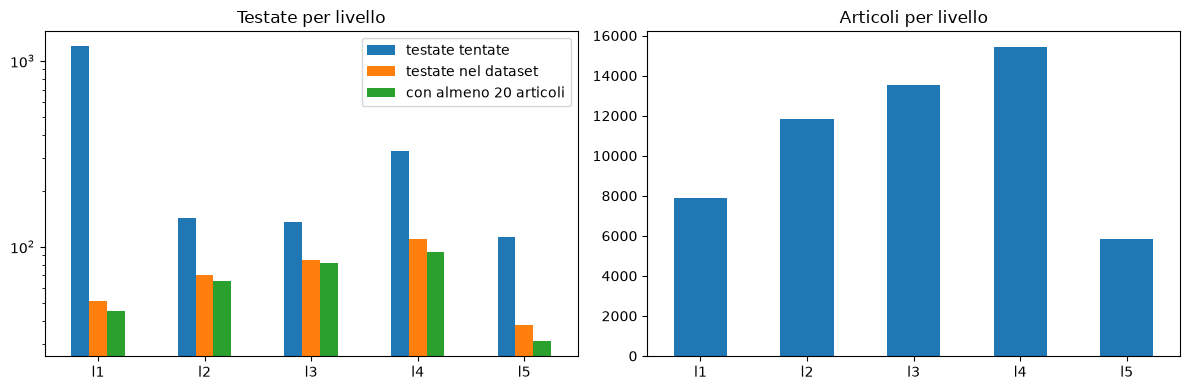

In [7]:
fig, assi = plt.subplots(1, 2, figsize=(12, 4))
composizione.drop("totale")[["testate tentate", "testate nel dataset", "con almeno 20 articoli"]].plot.bar(ax=assi[0], rot=0)
assi[0].set_title("Testate per livello"); assi[0].set_yscale("log")
composizione.drop("totale")["articoli"].plot.bar(ax=assi[1], rot=0, color="tab:blue")
assi[1].set_title("Articoli per livello")
plt.tight_layout(); plt.show()

## 4. Le date degli articoli

articoli con una data: 100%
count                         54531
mean     2025-02-04 19:09:02.861858
min             1995-04-20 00:00:00
25%             2026-02-11 00:00:00
50%             2026-09-10 00:00:00
75%             2026-10-05 00:00:00
max             2026-10-13 00:00:00
Name: data, dtype: object


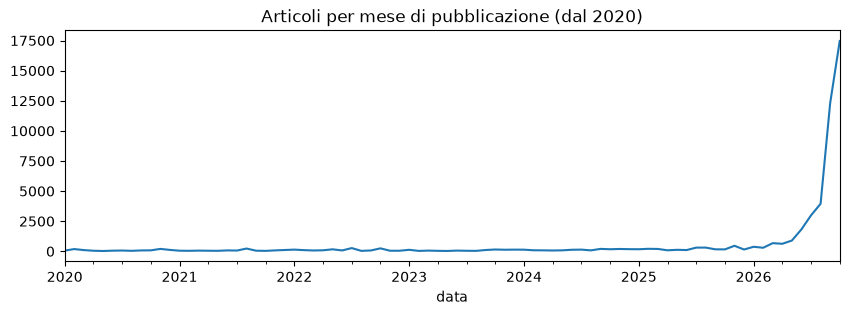

In [8]:
data = pd.to_datetime(articoli.data, errors="coerce")
print(f"articoli con una data: {data.notna().mean():.0%}")
print(data.describe())
data[data >= "2020-01-01"].dt.to_period("M").value_counts().sort_index().plot(figsize=(10, 3), title="Articoli per mese di pubblicazione (dal 2020)")
plt.show()

## 5. Confronto con il dataset vecchio (IrForGood)

In [10]:
vecchio = pd.read_csv("../EsperimentiPreliminari/1-PrimoDataset/Dataset/CleannedDataset/newDataframeWithOldCleanedPoliticsVersion.csv", usecols=["domain"]).domain
nuove, vecchie = set(articoli.dominio), set(vecchio)
print("testate in entrambi:", len(nuove & vecchie))
print("solo nel nuovo:", len(nuove - vecchie))
print("solo nel vecchio:", len(vecchie - nuove))

testate in entrambi: 226
solo nel nuovo: 128
solo nel vecchio: 213


## 6. Salvataggio

In [11]:
colonne = ["dominio", "url", "titolo", "data", "autore", "fonte", "parole", "testo", "score", "label"]
articoli[colonne].reset_index(drop=True).rename_axis("article_id").to_csv(CARTELLA + "dataset_articoli.csv")
print(len(articoli), "articoli,", articoli.dominio.nunique(), "testate")